# Aufgabe 11.3 – Saisonbereinigte Imputation mit STL

**APPROVED – AWAITING FINAL MERGE AUTHORIZATION.** Fachliches Review vom 26.10.2026 positiv. KI-Unterstützung: Codex erstellte Code, Erläuterungen, Tests und Export. Der studentische Originalreview ist unverändert in `reviews/exercise_11_3.md` dokumentiert.

Offizielle Quellen, am 26.10.2026 tatsächlich gelesen: [Aufgabe 11.3](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/7_self_study_session2.html), [Kapitel 6](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/2_1_timeseries_decomposition.html), [statsmodels STL](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html).

Ziel: fehlende Wochen zunächst einfach ergänzen, eine Saisonkomponente schätzen und anschließend die **ursprüngliche lückenhafte Medianreihe** saisonbereinigt imputieren. Danach die Saison zurückaddieren und den Unterschied zur einfachen Linearimputation diskutieren. Keine Ausreißerzählung und keine Aufgabe 11.4.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("Notebook vom Projektstamm ausführen")
sys.path.insert(0, str(ROOT))
from sessions.ch11.production import SHA256
from sessions.ch11.imputation import load_smoothed_input, INPUT_SHA256
from sessions.ch11.stl_imputation import stl_impute, summarize_stages, STL_CONFIG, FIT_CONFIG
from sessions.ch11.stl_plots import seasonal_decompose_seaborn, plot_deseasonalized, plot_final_production, plot_long_gap
sns.set_theme(style="whitegrid")
OUTPUT = ROOT / "outputs/ch11/exercise_11_3"
OUTPUT.mkdir(parents=True, exist_ok=True)
frame, source = load_smoothed_input()
original = source.copy()
print("statsmodels:", statsmodels.__version__)
print(f"Wochen: {len(source)}; bekannt: {source.notna().sum()}; fehlend: {source.isna().sum()}")
display(pd.DataFrame({"geglättete_Eingabe": source}).head(10))

statsmodels: 0.15.0
Wochen: 1044; bekannt: 677; fehlend: 367


,geglättete_Eingabe
Date,
2005-01-02,191.166551
2005-01-09,192.121879
2005-01-16,191.166551
2005-01-23,193.077208
2005-01-30,198.645442
2005-02-06,228.586036
2005-02-13,233.786982
2005-02-20,235.081313
2005-02-27,237.347377


## Daten und Wiederverwendung
Die offizielle synthetische Produktions-CSV bleibt unverändert. Die bestehende Hash-/Kalenderprüfung und der kanonische Hash des freigegebenen 11.1-Medians sichern dieselbe Eingabe ab: 1.044 Wochen vom 02.01.2005 bis 29.12.2024, 677 vorhandene und 367 fehlende Werte. Die längste Lücke umfasst 23 Wochen; es gibt keine Randlücken. Datenquelle und Lizenzgrenze stehen in `data/raw/PRODUCTION_SOURCE.md`.

Aus 11.2 wird ausschließlich die einfache lineare Imputationsfunktion wiederverwendet; das Endergebnis von 11.2 wird nicht als lückenfreie Ausgangsreihe missverstanden. Die vollständige Spalte `pieces` dient nur als grafischer Kontext, ist selbst gestört und keine fehlerfreie Referenz für die unbekannten Wochen. Keine Zufallsberechnung, daher kein Seed nötig.

## Additives Modell und zwei Imputationsstufen
STL bedeutet *Seasonal and Trend decomposition using LOESS*. Lokal gewichtete Regressionen schätzen Trend Tₜ und Saison Sₜ. Der Rest Rₜ ist ein Residuum, nicht automatisch weißes Rauschen.

1. **Vorläufig ergänzen:** y⁽⁰⁾ = L(y), wobei L lineare Interpolation zwischen bekannten Wochen ist. STL benötigt vollständige Eingabedaten.
2. **Zerlegen:** y⁽⁰⁾ₜ = Tₜ + Sₜ + Rₜ.
3. **Ursprüngliche Lücken zurückverwenden:** dₜ = yₜ − Sₜ. Bei fehlendem yₜ bleibt dₜ fehlend. Wir subtrahieren nicht von der bereits vervollständigten Vorstufe.
4. **Saisonbereinigt ergänzen:** d̂ = L(d).
5. **Saison zurückaddieren:** ŷₜ = d̂ₜ + Sₜ. An ursprünglich bekannten Wochen wird yₜ explizit wieder eingesetzt, um Rundungsänderungen durch Subtraktion/Addition zu vermeiden.

Nur fehlende Werte werden ersetzt. Die vorbereitende Linearimputation bestimmt die geschätzte Saison mit; das ist keine von Imputation unabhängige Messung der Saison.

### Dokumentierte Parameter
`period=52` approximiert ein jährliches Muster bei Wochendaten. Ein Kalenderjahr hat etwa 52,18 Wochen; über 20 Jahre können Phasenverschiebungen entstehen. Die Periode ist eine Modellannahme, keine entdeckte exakte Kalenderkonstante.

`seasonal=13` bezeichnet die ungerade LOESS-Fensterlänge auf den saisonalen Teilreihen (über Zyklen), **keinen 13-Wochen-Zyklus**. `trend=101` und `low_pass=53` sind ungerade Glättungsfenster, beide größer als die Periode. Die Fenster sind explizite plausible Einstellungen und nicht statistisch optimiert. LOESS-Grade bleiben beim dokumentierten Standard 1; Sprungweiten sind 1.

`robust=True`, zwei innere und 15 äußere Iterationen entsprechen den dokumentierten robusten Standarditerationen. Robuste Gewichtung kann den Einfluss einzelner Abweichungen verringern, garantiert aber keine korrekte Rekonstruktion. Additivität setzt eine auf absoluter Skala darstellbare Saison voraus; bei relativ zur Produktion wachsenden Ausschlägen wäre diese Wahl neu zu prüfen.

In [2]:
stages, decomposition = stl_impute(source)
summary = summarize_stages(stages)
pd.testing.assert_series_equal(source, original)
assert summary["same_deseasonalized_mask"]
assert summary["missing_deseasonalized"] == 367
assert summary["missing_final"] == 0
assert summary["observed_exactly_preserved"]
print("STL-Parameter:", STL_CONFIG, "Iterationen:", FIT_CONFIG)
display(stages[["smoothed_gaps", "preliminary_linear", "deseasonalized_gaps", "deseasonalized_linear", "final_imputed"]].isna().sum().rename("NaNs je Stufe").to_frame())

STL-Parameter: {'period': 52, 'seasonal': 13, 'trend': 101, 'low_pass': 53, 'robust': True} Iterationen: {'inner_iter': 2, 'outer_iter': 15}


,NaNs je Stufe
smoothed_gaps,367
preliminary_linear,0
deseasonalized_gaps,367
deseasonalized_linear,0
final_imputed,0


## Geschätzte Komponenten
Die Kursfunktion `seasonal_decompose_seaborn` wird mit deutschen Beschriftungen und Rückgabe der Figure verwendet. Das obere Teilbild zeigt die **vorläufig linear ergänzte** Eingabe, keine vollständige Messreihe. Alle Komponenten haben Stück pro Woche als Einheit; die y-Skalen unterscheiden sich. Die Zerlegung beschreibt diese vorbereitete Reihe, nicht die unbekannte Wahrheit innerhalb der Lücken.

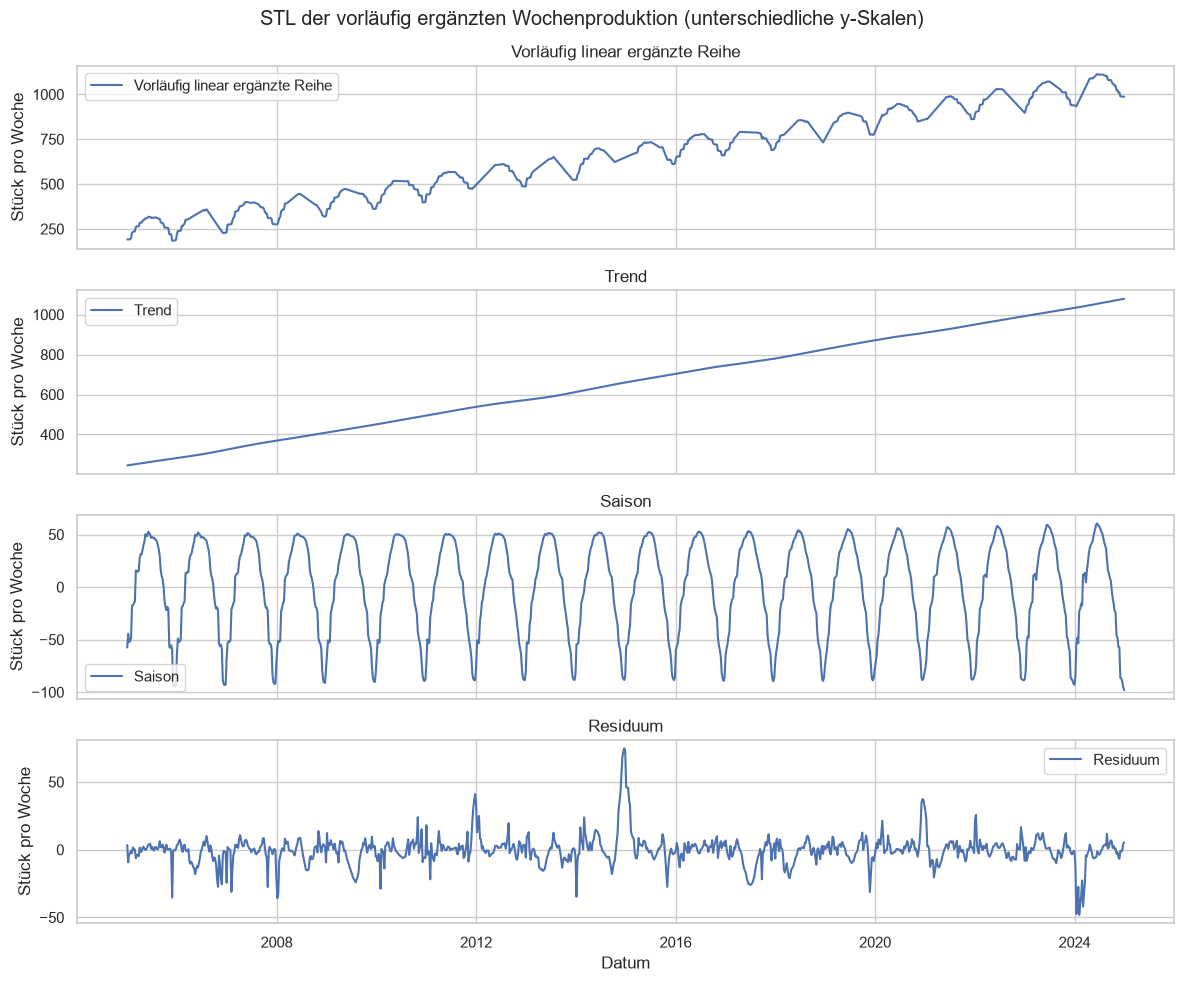

Maximaler additiver Rekonstruktionsrest: 1.1368683772161603e-13


In [3]:
fig = seasonal_decompose_seaborn(decomposition, "STL der vorläufig ergänzten Wochenproduktion")
fig.savefig(OUTPUT / "01_stl_components.png", dpi=140)
plt.show()
print("Maximaler additiver Rekonstruktionsrest:", summary["additive_reconstruction_max_abs"])

## Saisonabzug bei unveränderter Lückenstruktur
Nach Abzug der geschätzten Saison bleibt der Trend sichtbar. Die 367 fehlenden Wochen bleiben an exakt denselben Positionen offen. Eine glatter wirkende Kurve belegt keine höhere Genauigkeit. Die NaNs werden im Linienpfad erhalten, damit getrennte beobachtete Abschnitte nicht durch Seaborn überbrückt werden.

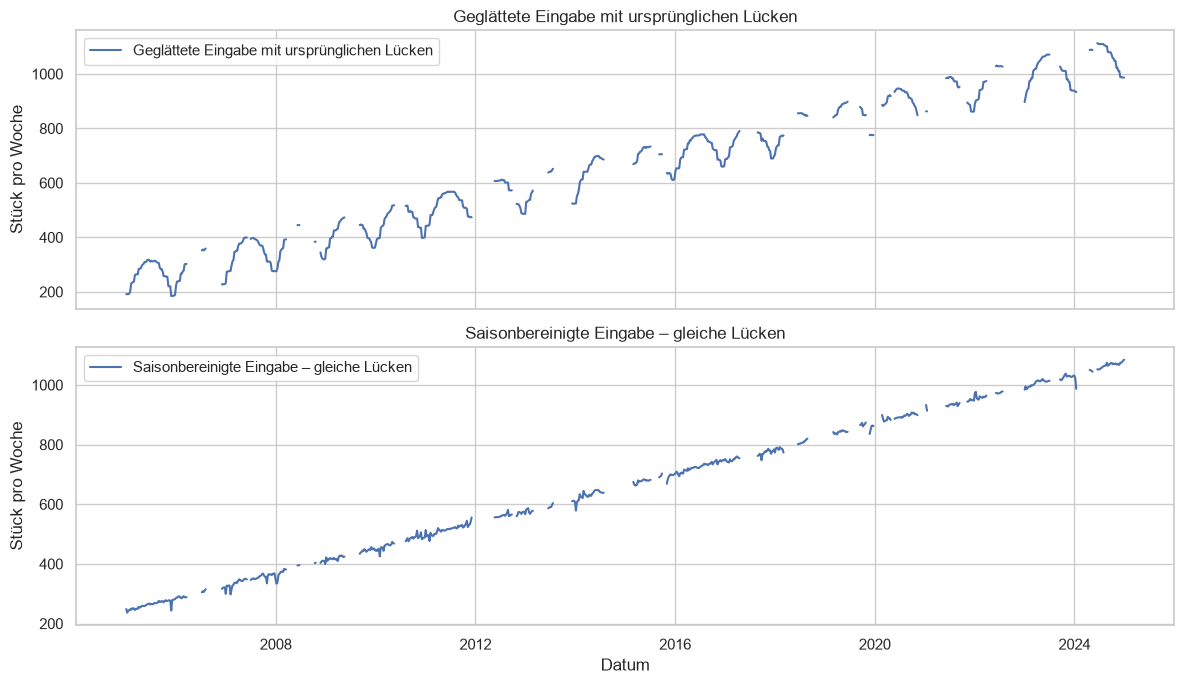

In [4]:
fig = plot_deseasonalized(stages)
fig.savefig(OUTPUT / "02_deseasonalized_gaps.png", dpi=140)
plt.show()

## Endgültige Ergänzung und Rückaddition der Saison
Die dreiteilige `plot_production_data`-Kursdarstellung trennt vollständige Kontextreihe, geglättete Eingabe mit Lücken und ausschließlich ergänzte Wochen. Die 11.3-spezifische Anpassung beschriftet diese Stufen eindeutig und erhält NaN-Unterbrechungen im dritten Teilbild. Eine vollständige Ergebnisreihe darf nicht mit einer vollständig beobachteten Reihe verwechselt werden.

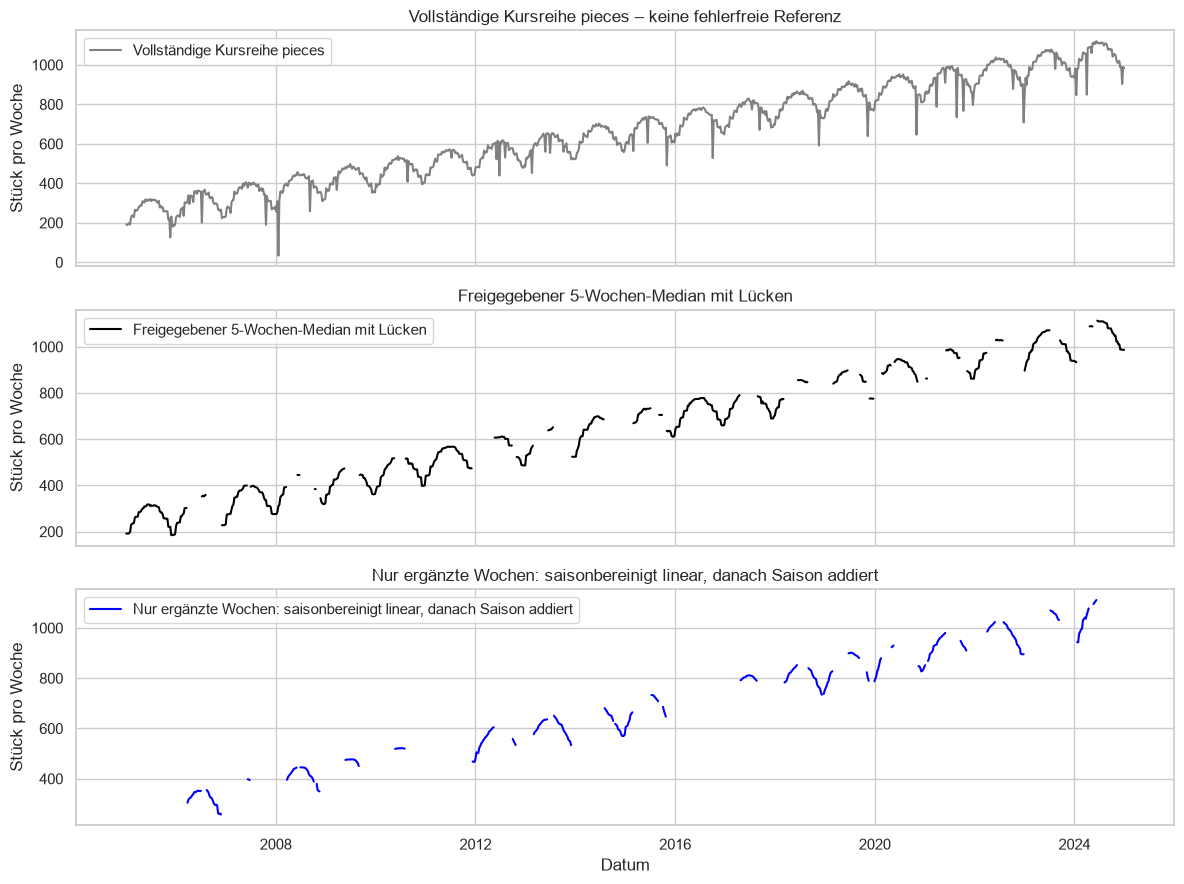

In [5]:
fig = plot_final_production(frame, stages)
fig.savefig(OUTPUT / "03_final_imputation.png", dpi=140)
plt.show()

## Unterschied zur einfachen Linearimputation an einer langen Lücke
Der Ausschnitt wird über die erste längste Lücke (11.12.2011–13.05.2012, 23 Wochen) festgelegt. Die graue Fläche markiert fehlende Wochen, schwarze Punkte die vorhandenen Medianwerte. Das untere Teilbild zeigt die Differenz der beiden Schätzverfahren nur an Fehlstellen. Sie ist **kein Schätzfehler** gegen wahre Werte.

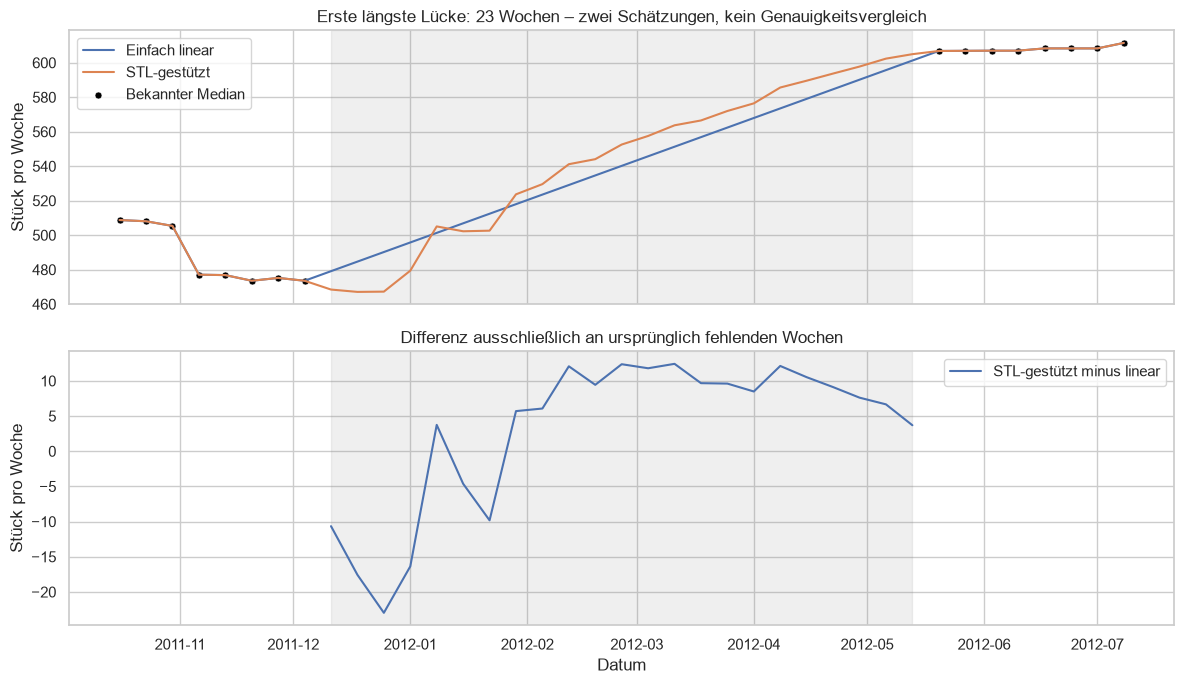

,Berechnete Stufenprüfung
rows,1044
observed,677
missing_input,367
missing_preliminary,0
missing_deseasonalized,367
same_deseasonalized_mask,True
missing_final,0
observed_exactly_preserved,True
additive_reconstruction_max_abs,1.13687e-13
difference_from_linear_mean_abs_at_gaps,9.7462


In [6]:
fig = plot_long_gap(stages)
fig.savefig(OUTPUT / "04_long_gap_comparison.png", dpi=140)
plt.show()
display(pd.Series(summary, name="Berechnete Stufenprüfung").map(
    lambda value: f"{value:.6g}" if isinstance(value, float) else value
).to_frame())

## Beobachtung, Interpretation und Grenzen
Der langfristige Anstieg liegt überwiegend im Trend. Die geschätzte Saison beschreibt wiederkehrende Schwankungen; im Residuum bleiben Abweichungen von diesem additiven Modell. Im gezeigten Langlückenausschnitt fällt die STL-gestützte Kurve zunächst unter den linken Stützwert und liegt später über der linearen Schätzung. Das folgt der geschätzten Saison und belegt nicht den tatsächlichen Produktionsverlauf. Die berechneten mittleren und maximalen absoluten Differenzen beziehen sich ausschließlich auf ursprünglich fehlende Wochen; sie messen Methodenunterschiede, keine Genauigkeit. Über alle 367 Fehlwochen betragen sie hier im Mittel 9,746 und maximal 75,247 Stück pro Woche.

Die additive Rekonstruktionsidentität kontrolliert die Zerlegung numerisch. Sie beweist nicht, dass Trend und Saison inhaltlich eindeutig oder richtig geschätzt sind. Die vorläufig ergänzten 35,15 % der Wochen fließen in die STL-Schätzung ein. Lange Ausfälle können die Saison verzerren; robuste Gewichtung verhindert das nicht zuverlässig. Auch Randwochen und die ungefähre 52-Wochen-Periode begrenzen die Interpretation.

Das Verfahren wird genau einmal ausgeführt, ohne iterative Parameteroptimierung oder behauptete Unsicherheitsintervalle. Das 11.1-Medianfilter kann reale kurze Ereignisse bereits gedämpft haben. Alle Schritte sind rückblickend: Zentrierung und spätere Interpolationsstützstellen wären in einer unverändert übernommenen Echtzeitprognose Leakage. Für Prognosen wären chronologische Splits und ausschließlich im jeweiligen Trainingsstand berechnete Vorverarbeitung erforderlich.

Für den Managementbericht sollten ergänzte Werte als Schätzungen gekennzeichnet und Aussagen über lange Lücken vorsichtig formuliert werden. Ob die gewählten Periode/Fenster und die additive Saison fachlich angemessen sind, bleibt Gegenstand des studentischen Reviews.

In [7]:
stages.to_csv(ROOT / "data/processed/exercise_11_3_stages.csv")
stages[["preliminary_linear", "trend", "seasonal", "residual"]].to_csv(OUTPUT / "components.csv")
stages.isna().sum().rename("missing").to_csv(OUTPUT / "stage_missing_counts.csv")
record = {**summary, "stl_config": STL_CONFIG, "fit_config": FIT_CONFIG,
          "raw_sha256": SHA256, "approved_smoothed_input_sha256": INPUT_SHA256,
          "statsmodels_version": statsmodels.__version__}
(OUTPUT / "summary.json").write_text(json.dumps(record, indent=2) + "\n", encoding="utf-8")
print("Erzeugt: Komponenten, Stufen-CSV, NaN-Tabelle und summary.json")

Erzeugt: Komponenten, Stufen-CSV, NaN-Tabelle und summary.json


## Konkrete Fragen für dein wissenschaftliches Review
1. Ist klar, weshalb die erste Imputation nur STL ermöglicht und der zweite Schritt wieder die ursprünglichen 367 Lücken verwendet?
2. Sind additive Saison, die Näherung von 52 Wochen und die expliziten LOESS-Fenster für den Bericht nachvollziehbar begründet?
3. Ist die Trennung zwischen Rekonstruktionsidentität, Methodenunterschied und unbekannter Genauigkeit verständlich?
4. Welche Aussage über die 23-Wochen-Lücke wäre im Managementbericht vertretbar?

Status und echte technische Nachweise: `reviews/exercise_11_3.md`. Positive fachliche Freigabe dokumentiert; finale Merge-Autorisierung ausstehend. Kein Merge und keine Arbeit an 11.4.